# Predecir el coste del seguro médico de una persona

In [43]:
#Librerias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

## Paso 1: Carga del conjunto de datos

In [3]:
df = pd.read_csv('https://breathecode.herokuapp.com/asset/internal-link?id=929&path=medical_insurance_cost.csv')

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Paso 2: Realiza un EDA completo

### 1er Paso EDA: Planteamiento del problema y recopilación de datos

La importante compañía de seguros 4Geeks Insurance S.L. quiere calcular (predecir), en función de los datos fisiológicos de sus clientes, cuál va a ser la prima (coste) que debe asumir cada uno de ellos. Para ello, ha reunido a un equipo completo de médicos y en función de datos de otras compañías y un estudio particular han logrado reunir un conjunto de datos para entrenar un modelo predictivo. (regresión lineal)

### 2do Paso: Exploración y limpieza de datos

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


- Nuestro dataframe tiene 1.338 observaciones y 7 variables. Para el modelo de regresión, vamos a tomar como variable dependiente **'charges'** y como predictoras todas las restantes. 

- Nuestras variables numéricas son 4: **'age'**, **'bmi'**, **'children'** y nuestra objetivo **'charges'**. 

- Nuestras variables categóricas son 3: **'sex'**, **'smoker'** y **'region'**.

- Por otro lado podemos ver que no hay valores nulos y que el número de filas es de 1.338, que corresponden al número de registros de personas.

In [8]:
categoricas = df.select_dtypes(include='str').columns
categoricas

Index(['sex', 'smoker', 'region'], dtype='str')

In [9]:
numericas = df.select_dtypes(exclude='str').columns
numericas

Index(['age', 'bmi', 'children', 'charges'], dtype='str')

**Eliminar duplicados**

In [5]:
df.duplicated().sum()

np.int64(1)

Tenemos un duplicado, asi que lo eliminaremos.

In [6]:
if df.duplicated().sum():
    df = df.drop_duplicates()
    
df.shape

(1337, 7)

Ahora nos correspondería eliminar la información irrelevante, pero consideramos que no hay variables irrelevantes para descartar ya que no tenemos identificadores, nombres, etc.

### 3er Paso: Análisis de variables univariante

Antes de empezar el análisis, convertiremos nuestras variables categóricas a numéricas, ya que para nuestro modelo de regresión lineal necesitamos que todas nuestras variables sean numéricas.

In [10]:
for columna in categoricas:
    df[columna] = pd.factorize(df[columna])[0]

df.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   int64  
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   int64  
 5   region    1337 non-null   int64  
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(5)
memory usage: 83.6 KB


Ahora sigamos con nuestro análisis univariante **numérico**

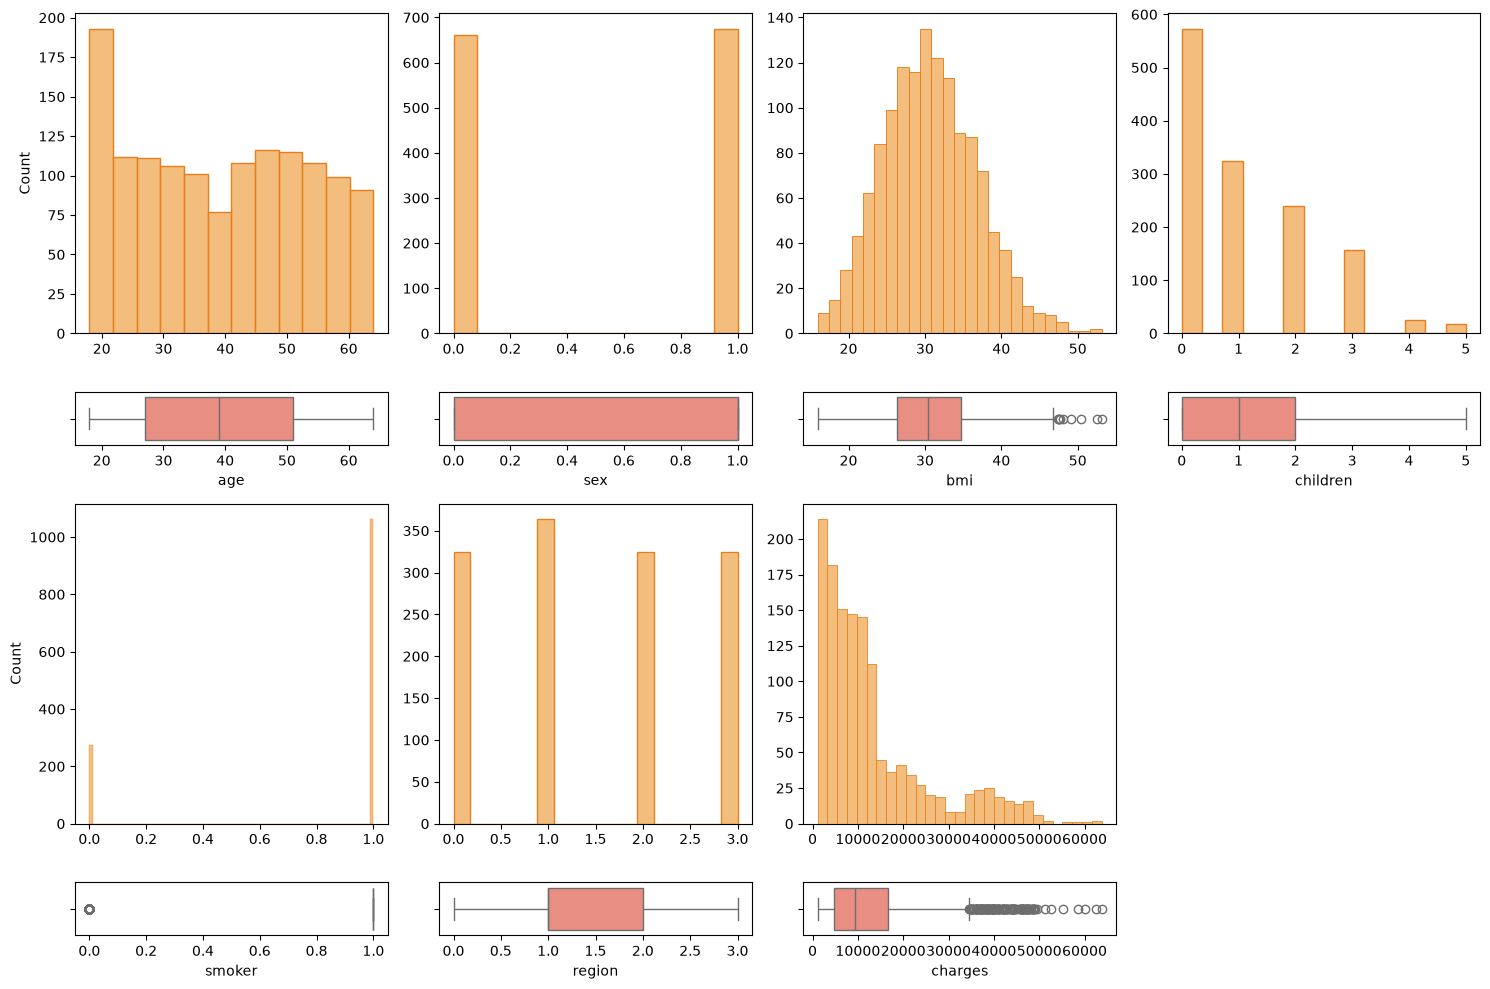

In [18]:
fig, axis = plt.subplots(4, 4, figsize = (15, 10), gridspec_kw={'height_ratios': [6, 1, 6, 1]})

sns.histplot(ax = axis[0, 0], data = df, x = "age", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None)
sns.boxplot(ax = axis[1, 0], data = df, x = "age", color='salmon')
sns.histplot(ax = axis[0, 1], data = df, x = "sex", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[1, 1], data = df, x = "sex", color='salmon')
sns.histplot(ax = axis[0, 2], data = df, x = "bmi", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[1, 2], data = df, x = "bmi", color='salmon')
sns.histplot(ax = axis[0, 3], data = df, x = "children", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[1, 3], data = df, x = "children", color='salmon')
sns.histplot(ax = axis[2, 0], data = df, x = "smoker", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None)
sns.boxplot(ax = axis[3, 0], data = df, x = "smoker", color='salmon')
sns.histplot(ax = axis[2, 1], data = df, x = "region", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[3, 1], data = df, x = "region", color='salmon')
sns.histplot(ax = axis[2, 2], data = df, x = "charges", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[3, 2], data = df, x = "charges", color='salmon')

fig.delaxes(axis[2,3])
fig.delaxes(axis[3,3])

plt.tight_layout()

plt.show()

### 4to Paso: Análisis de variables multivariante

Haremos nuestro análisis **numérico-numérico**, y así ver la correlación de nuestras predictoras con nuestra objetivo.

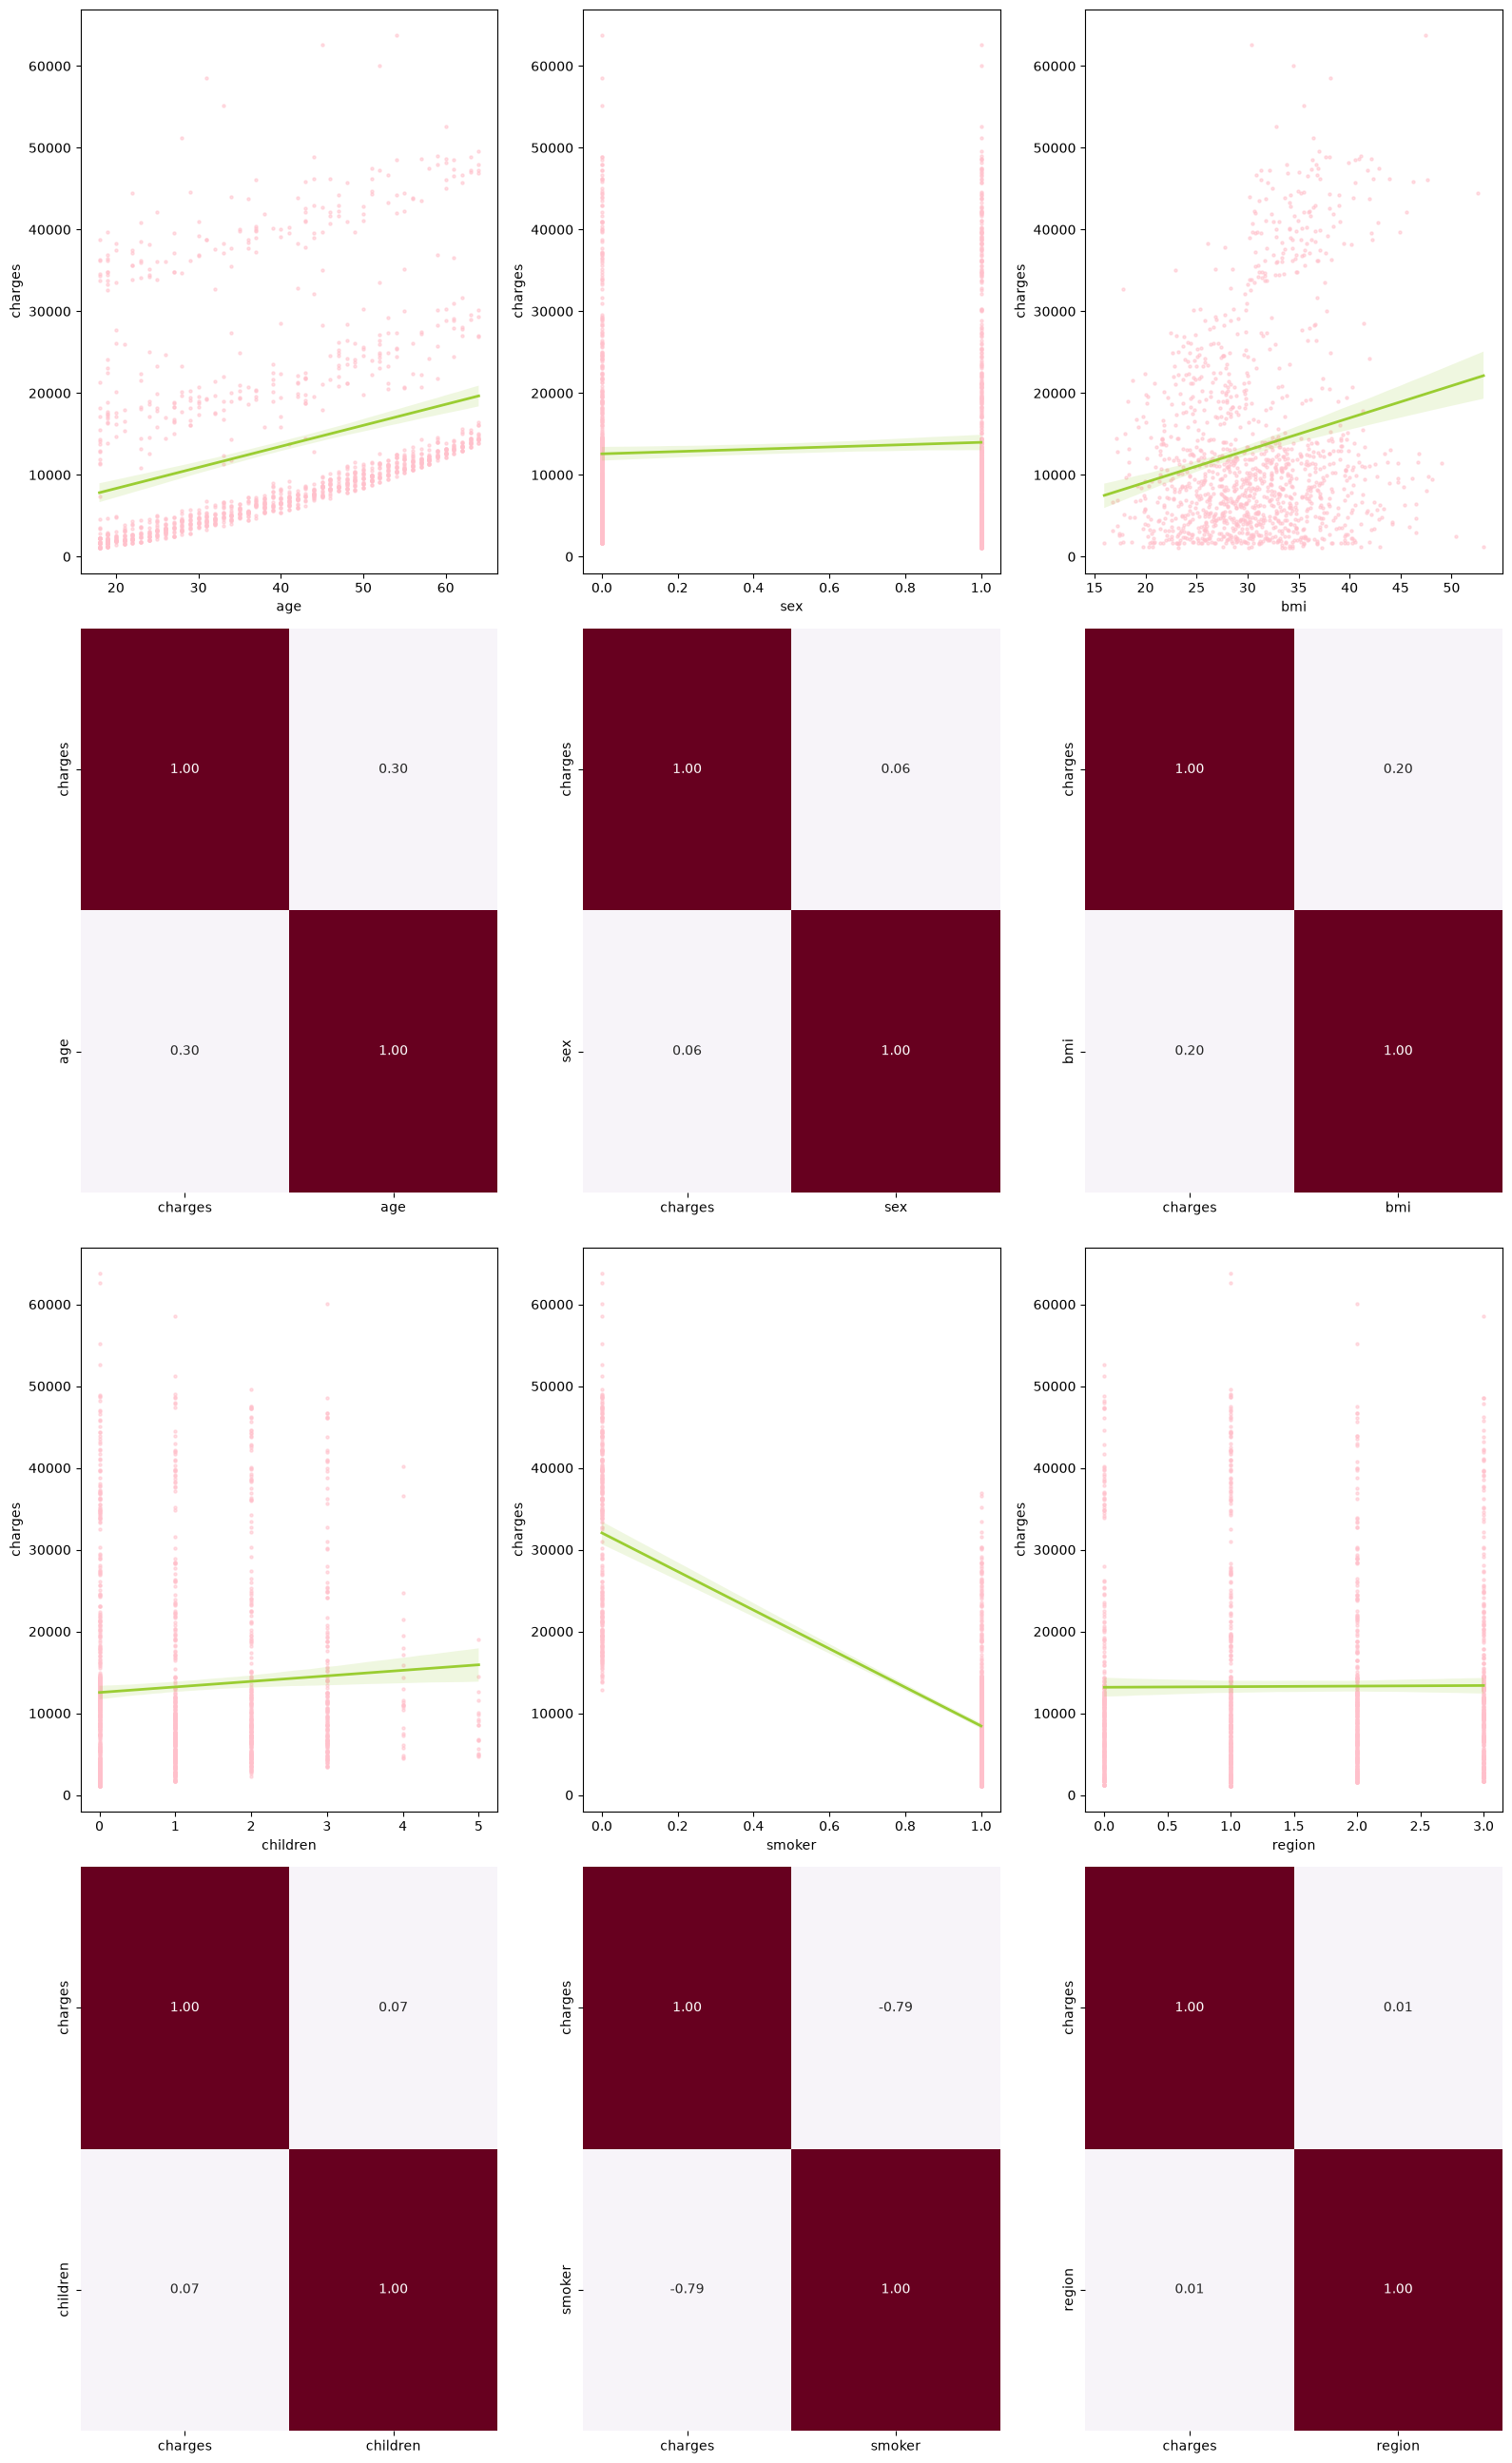

In [19]:
fig, axis = plt.subplots(4,3, figsize=(16,26))

sns.regplot(ax = axis[0,0], data = df, x = "age", y = "charges", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["charges","age"]].corr(), annot=True, fmt = '.2f', ax = axis[1,0], cmap='PuRd', cbar=False)

sns.regplot(ax = axis[0,1], data = df, x = "sex", y = "charges", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["charges","sex"]].corr(), annot=True, fmt = '.2f', ax = axis[1,1], cmap='PuRd', cbar=False)

sns.regplot(ax = axis[0,2], data = df, x = "bmi", y = "charges", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["charges","bmi"]].corr(), annot=True, fmt = '.2f', ax = axis[1,2], cmap='PuRd', cbar=False)

sns.regplot(ax = axis[2,0], data = df, x = "children", y = "charges", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["charges","children"]].corr(), annot=True, fmt = '.2f', ax = axis[3,0], cmap='PuRd', cbar=False)

sns.regplot(ax = axis[2,1], data = df, x = "smoker", y = "charges", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["charges","smoker"]].corr(), annot=True, fmt = '.2f', ax = axis[3,1], cmap='PuRd', cbar=False)

sns.regplot(ax = axis[2,2], data = df, x = "region", y = "charges", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["charges","region"]].corr(), annot=True, fmt = '.2f', ax = axis[3,2], cmap='PuRd', cbar=False)
            
plt.tight_layout()

plt.show()

Y para complementar, haremos una matriz de correlación para ver si hay multicolinealidad.

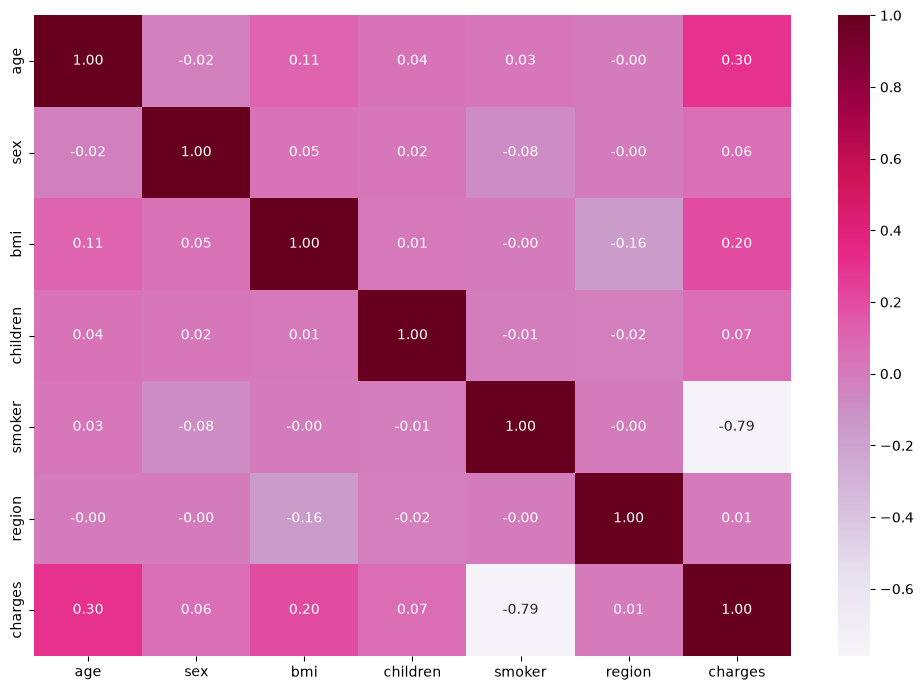

In [20]:
fig, ax = plt.subplots(figsize=(10,7))
sns.heatmap(df.corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax)
plt.tight_layout()
plt.show()

Podemos observar que con respecto a nuestra objetivo tenemos variables con **CASI NULA** correlación como **'sex'**, **'children'** y **'region'**. También tenemos otras con un poco más de correlación, que son con las variables que nos quedaremos ya que tampoco tienen correlación entre ellas: **'age'**, **'bmi'** y **'smoker'**.

In [22]:
df_limpio = df[['age', 'bmi', 'smoker', 'charges']]
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,0,0,16884.92400
1,18,1,33.770,1,1,1,1725.55230
2,28,1,33.000,3,1,1,4449.46200
3,33,1,22.705,0,1,2,21984.47061
4,32,1,28.880,0,1,2,3866.85520


Ahora dibujaremos nuestro pairplot

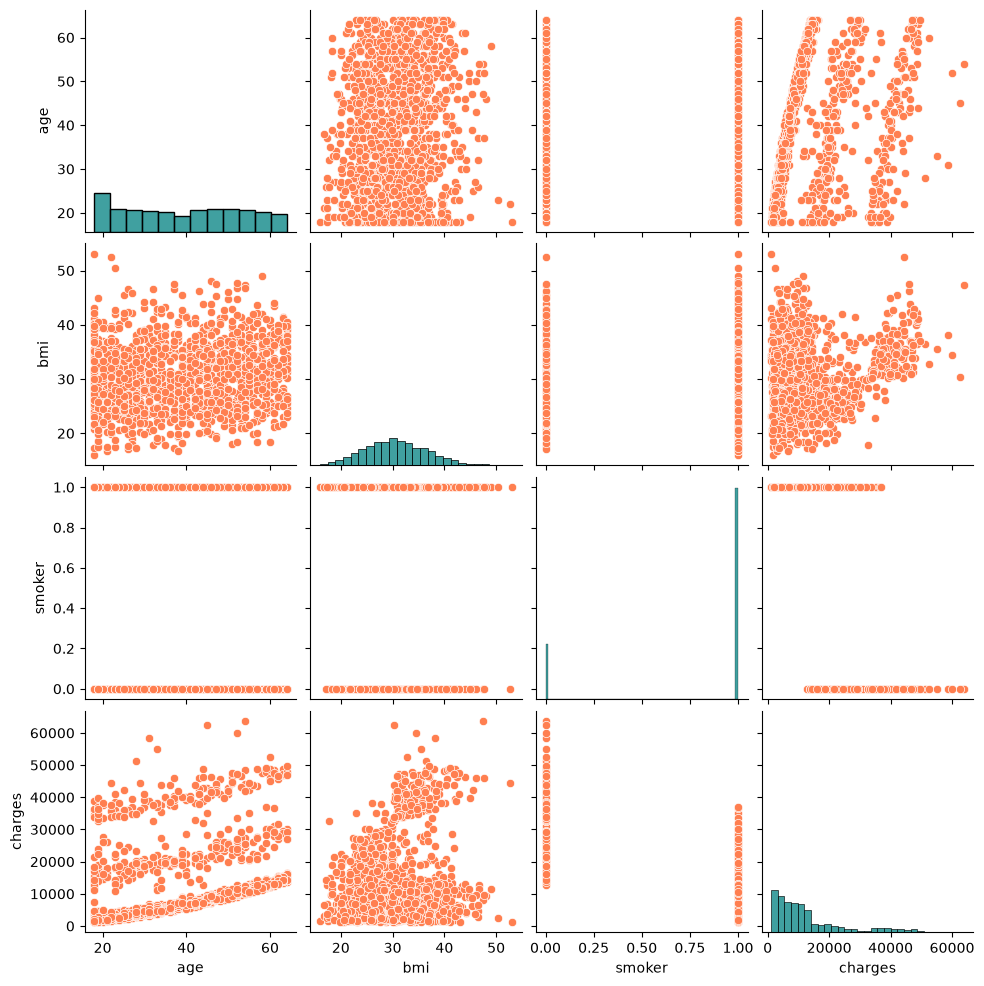

In [24]:
sns.pairplot(data = df_limpio, plot_kws={'color': 'coral'}, diag_kws={'color': 'teal'})
plt.show()

### 5to Paso: Ingeniería de características

**Análisis de Outliers**

In [26]:
df_limpio.describe()

,age,bmi,smoker,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,0.795064,13279.121487
std,14.044333,6.100468,0.403806,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,1.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,1.000000,16657.717450
max,64.000000,53.130000,1.000000,63770.428010


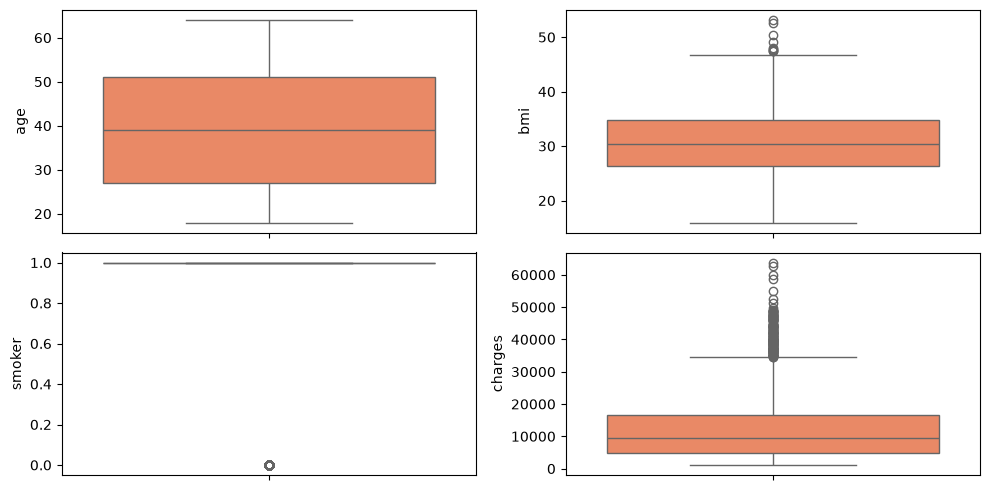

In [33]:
fig, axis = plt.subplots(2, 2, figsize = (10, 5))

sns.boxplot(ax = axis[0,0], data = df_limpio, y = 'age', color = 'coral')
sns.boxplot(ax = axis[0,1], data = df_limpio, y = 'bmi', color = 'coral')
sns.boxplot(ax = axis[1,0], data = df_limpio, y = 'smoker', color = 'coral')
sns.boxplot(ax = axis[1,1], data = df_limpio, y = 'charges', color = 'coral')

plt.tight_layout()

plt.show()

Pese a tener outliers, los mantendremos.

**Análisis de valores faltantes**

In [34]:
df_limpio.isnull().sum().sort_values(ascending=False)

age        0
bmi        0
smoker     0
charges    0
dtype: int64

No tenemos valores faltantes ni tampoco haremos inferencia de nuevas características.

**Separación de Train y test**

In [36]:
X= df_limpio.drop(columns=['charges'])
y= df_limpio['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y , test_size= 0.20, random_state=42)

X_train.head()

,age,bmi,smoker
1114,23,24.510,1
968,21,25.745,1
599,52,37.525,1
170,63,41.470,1
275,47,26.600,1


**Escalado de valores**

Ya que no tenemos una distribución normal en todas nuestras variables, utilizaremos el escalado Mínimo-Máximo

In [38]:
scaler= MinMaxScaler()

X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

X_train_esc = pd.DataFrame(X_train_esc, columns=X_train.columns, index=X_train.index)
X_test_esc = pd.DataFrame(X_test_esc, columns=X_test.columns, index= X_test.index)

## Paso 3: Construye un modelo de regresión lineal

In [40]:
model= LinearRegression()

model.fit(X_train_esc, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 11586.3 , 11329.51,-23074.26]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['age','bmi','smoker']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.17e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [41]:
print(f'Intercepto:{model.intercept_}')
print(f'Coeficientes:{model.coef_}')

Intercepto:21701.79391257018
Coeficientes:[ 11586.30415359  11329.51105637 -23074.26173498]


In [42]:
y_pred = model.predict(X_test_esc)

y_pred

array([ 8433.67443577,  4336.46678013, 13165.0382606 , 30593.69534864,
        8738.64384303, 13004.1887831 , 29273.63576136,  2177.09021482,
       10922.95093736, 10315.83022735, 11021.84491859, 33740.33309282,
       30613.92158231, 18004.87150727,  9656.23179762,  9311.37354392,
        4325.12010919, 32099.96630635,  3001.71338943,  5552.62898392,
        4325.12010919, 29913.00795743, 14580.01800456, 30752.45719245,
       31444.92261851,  4769.02189756, 35187.05259131, 37413.46842278,
       10952.8675722 , 12177.75978526,  6505.9651105 , 13121.95183512,
         870.87899962, 12471.87695664, 40355.37672202, 12499.04467281,
        2732.11267963,  2866.20850841, 32023.18474965,  9365.1280589 ,
        6903.0538664 , 29243.81679061, 34097.79751626, 11919.91981386,
        6896.22734444,  4145.55111435,  6040.33037213,  9173.38425823,
        4186.69945959,  8909.59778913,  6340.1295272 , 12053.6361681 ,
       30836.41015271,  4425.70495311, 10719.84316929,  9666.05445578,
      

In [44]:
print(f'RMSE:{root_mean_squared_error(y_test, y_pred)}')
print(f'R2:{r2_score(y_test, y_pred)}')

RMSE:5986.783344847844
R2:0.8049502474643171


El **RMSE** nos da una idea de que tan lejos están nuestras predicciones de los valores reales, que en este caso se equivoca en casi 6.000, mientras que el **R2** nos da una idea de que tan bien se ajusta nuestro modelo a los datos y en este caso tenemos un **R2** del 80%, por lo que no es tan buen modelo para esta predicción (sería un buen modelo si es que fuera sobre 90%). Con correlaciones más altas, tendríamos un mejor **RMSE** y **R2**. Eran un poquito bajas las correlaciones en este caso para este modelo, pero no teníamos más
